# 3. Reinforcement learning

This tutorial trains a learning agent in GLASS and evaluates it fairly:
the Gymnasium environment, a short MaskablePPO training run, evaluation on
held-out seeds against baselines, putting the trained agent into any market,
customizing the observation, actions and reward, and several learners at
once through PettingZoo.

**Setup**: `pip install -e ".[rl,analysis]"` (installs PyTorch through
Stable-Baselines3). Runtime: about five minutes on a laptop.

The training budget is kept small so the notebook runs in a few minutes.
For your own experiments, raise `timesteps` and the number of training
seeds, or use `glass train` from the command line (see the user guide).

Contents:
1. The environment
2. Rewards: exit value
3. Train an agent
4. Evaluate on held-out seeds
5. The trained agent inside any market
6. Your own observation, actions and reward
7. Several learners: PettingZoo and IPPO

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from glass_sim.rl import ActionConfig, EnvConfig, PerpTradingEnv, exit_value

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (11, 3.5)
RUNS = Path("runs")

## 1. The environment

`PerpTradingEnv` adds one learning agent (`rl_01`, 100,000 of capital) to a
scenario. Each step is one decision: the agent wakes on its own random clock
(every 5 s on average), picks an action, and the market runs until its next
wakeup. An episode is one market; each episode uses the next seed from
`train_seeds`, so the agent never trains on the seeds we evaluate it on.

In [2]:
env_config = EnvConfig(scenario="default", episode_duration=1800.0, train_seeds=tuple(range(1000, 1200)))
env = PerpTradingEnv(env_config)
obs, info = env.reset()
print("observation:", env.observation_space, "| actions:", env.action_space, "| market seed:", info["market_seed"])
pd.Series(obs, index=env.encoder.feature_names).round(3).to_frame("value")

observation: Box(-5.0, 5.0, (32,), float32) | actions: Discrete(9) | market seed: 1000


,value
spread_bps,0.500
mid_vs_index_bps,-0.052
mark_vs_index_bps,-0.052
return_10s_bps,0.000
return_60s_bps,0.000
return_300s_bps,0.000
index_return_60s_bps,0.077
volatility_60s_bps,0.000
book_imbalance_5,-0.325
log_depth_bid,1.495


The 32 features describe the market (spread, basis, returns, volatility,
book imbalance, taker flow, funding, open interest, news), the agent's own
account (leverage, PnL, margin, distance to liquidation, resting orders) and
a transparency block (aggregate positioning, liquidation clusters, the
largest account, the strongest flow) that is zero when the transparency
level hides it.

The 9 actions come with a validity mask: an action is invalid when it cannot
work (no liquidity on that side, it would exceed the 10x exposure cap,
nothing to cancel or close). `MaskablePPO` never samples invalid actions.

In [3]:
pd.DataFrame({"action": env.actions.names, "valid now": env.action_masks()})

,action,valid now
0,hold,True
1,buy_small,True
2,buy_large,True
3,sell_small,True
4,sell_large,True
5,bid_at_touch,True
6,ask_at_touch,True
7,cancel_all,False
8,close_position,False


## 2. Rewards: exit value

The reward is the change, between two decisions, of the account's *exit
value*: what it would be worth if it closed its position right now against
the real order book, after the taker fee. Fees, funding and liquidation
losses flow in automatically, and opening a position costs reward at once
(half the spread plus fees). One unit is 1% of the initial capital.

Two simple policies on the same seed, `hold` and uniformly random valid
actions:

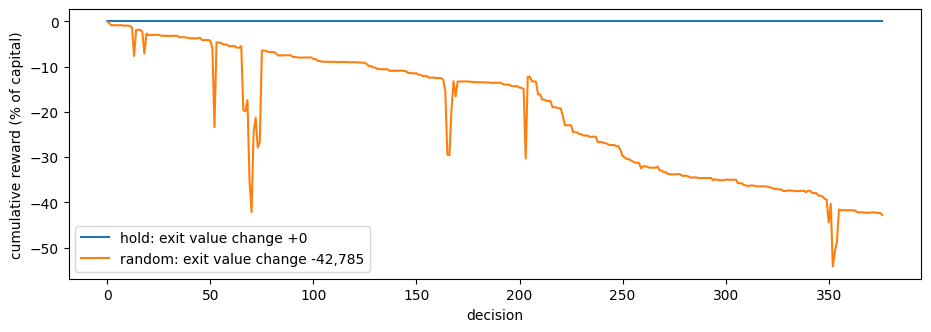

In [4]:
def play(policy, seed=7):
    env = PerpTradingEnv(env_config)
    env.reset(options={"market_seed": seed})
    start = exit_value(env.market, "rl_01")
    rewards, done = [], False
    rng = np.random.default_rng(0)
    while not done:
        _, reward, terminated, truncated, info = env.step(policy(env.action_masks(), rng))
        rewards.append(reward)
        done = terminated or truncated
    change = exit_value(env.market, "rl_01") - start
    return np.cumsum(rewards), change


hold = lambda mask, rng: 0
random_valid = lambda mask, rng: int(rng.choice(np.flatnonzero(mask)))

fig, ax = plt.subplots()
for name, policy in (("hold", hold), ("random", random_valid)):
    curve, change = play(policy)
    ax.plot(curve, label=f"{name}: exit value change {change:+,.0f}")
ax.set_xlabel("decision"); ax.set_ylabel("cumulative reward (% of capital)"); ax.legend()
plt.show()

Trading costs (fees and the spread) show up in the reward immediately. The
sharp dips are moments when the book is thin: closing a large position
there would be expensive, so the exit value drops until liquidity returns.
`hold` earns exactly zero, which makes it a natural reference point.

## 3. Train an agent

`train` runs MaskablePPO with parallel environments and writes a run
directory: `model.zip`, `config.json` (everything needed to rebuild the
agent) and `training_log.csv` (one row per episode).

In [5]:
from glass_sim.rl.train import train

run_dir = train("tutorial_agent", env_config, timesteps=60_000, n_envs=8, out_root=str(RUNS), checkpoint_every=10**9)
log = pd.read_csv(run_dir / "training_log.csv")
print(f"{len(log)} episodes in {pd.read_json(run_dir / 'config.json', typ='series')['training_seconds']:.0f} s")
log[["timesteps", "return", "pnl_pct", "liquidations"]].tail()

177 episodes in 92 s


,timesteps,return,pnl_pct,liquidations
172,63840,-19.353,-19.353,0.0
173,64000,-12.832,-12.832,0.0
174,64176,-13.846,-13.800,0.0
175,64312,-9.420,-9.389,0.0
176,65472,-25.501,-25.335,0.0


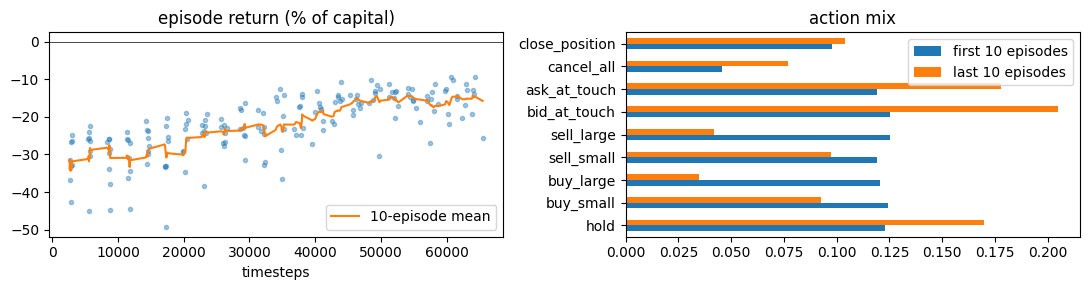

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3))
a.plot(log["timesteps"], log["return"], ".", alpha=0.4)
a.plot(log["timesteps"], log["return"].rolling(10, min_periods=1).mean(), label="10-episode mean")
a.axhline(0, color="k", lw=0.5); a.set_xlabel("timesteps"); a.set_title("episode return (% of capital)"); a.legend()
mix = log[[c for c in log.columns if c.startswith("act_")]]
early, late = mix.head(10).mean(), mix.tail(10).mean()
pd.DataFrame({"first 10 episodes": early, "last 10 episodes": late}).rename(index=lambda c: c[4:]).plot.barh(ax=b)
b.set_title("action mix"); plt.tight_layout(); plt.show()

Training returns start near those of the random agent and climb as the
policy learns to trade less and to quote instead of crossing the spread.
During training the policy samples actions to explore; the evaluation below
uses its most likely action. The learning curve and the action mix are the
first things to look at in any training run.

## 4. Evaluate on held-out seeds

`evaluate` runs the trained model and several controls on seeds it never
saw. Every treatment of a seed sees the same world, so the comparison is
paired:

- `model`: the trained policy;
- `scripted_mm`: the scripted market maker with the same capital and wake rate;
- `random`, `hold`: the simple baselines.

In [7]:
from glass_sim.rl.evaluate import evaluate

report = evaluate(str(run_dir), seeds=range(31, 37), duration=1800.0, treatments=("model", "scripted_mm", "random", "hold"), progress=False)
rows = [{"seed": r["seed"], "treatment": r["treatment"], **{k: r["learner"][k] for k in ("return_pct", "fees_paid", "trade_count", "max_leverage")}} for r in report["rows"]]
evaluation = pd.DataFrame(rows)
evaluation.pivot(index="seed", columns="treatment", values="return_pct")

treatment,hold,model,random,scripted_mm
seed,,,,
31,0.0,-1.154,-25.399,-0.220
32,0.0,-1.097,-30.747,0.648
33,0.0,2.415,-35.081,0.664
34,0.0,0.823,-31.342,0.344
35,0.0,-0.962,-31.143,0.367
36,0.0,-0.301,-41.649,0.886


In [8]:
evaluation.groupby("treatment")[["return_pct", "fees_paid", "trade_count", "max_leverage"]].median()

,return_pct,fees_paid,trade_count,max_leverage
treatment,,,,
hold,0.000,0.000,0.0,0.000
model,-0.632,780.508,223.5,2.646
random,-31.243,12598.253,1230.0,8.324
scripted_mm,0.507,176.712,333.0,1.185


In [9]:
model_row = next(r for r in report["rows"] if r["treatment"] == "model")
pd.Series(model_row["learner"]["actions"], name="share of decisions").sort_values(ascending=False).to_frame().T

,hold,bid_at_touch,ask_at_touch,close_position,cancel_all,buy_small,buy_large,sell_small,sell_large
share of decisions,0.631,0.194,0.107,0.062,0.006,0.0,0.0,0.0,0.0


This is the evaluation protocol: held-out seeds, paired treatments, and
controls that include a scripted strategy. The same cells work for any
trained agent, whatever its budget, observation or action menu.
`glass evaluate` produces the same comparison, with market-quality metrics,
from the command line.

## 5. The trained agent inside any market

`policy_agent_from_checkpoint` rebuilds the agent exactly as it was trained
(observation, action menu, wake rate). It is an ordinary `Agent`, so it can
join any scenario, at any transparency level, next to any other agents.

In [10]:
from glass_sim import PerpetualMarket, Transparency, parse_duration, scenarios
from glass_sim.rl.policy import policy_agent_from_checkpoint

agent = policy_agent_from_checkpoint(run_dir / "model.zip")
market = PerpetualMarket(scenarios.volatile(seed=5, duration=parse_duration("1h"), transparency=Transparency.ATTRIBUTED))
market.add_agent(agent, 100_000.0)
result = market.run()
table = pd.DataFrame(result.agent_table()).set_index("agent_id")
table.loc[[agent.agent_id], ["agent_type", "return_pct", "fees_paid", "trade_count", "max_abs_position", "liquidations"]]

,agent_type,return_pct,fees_paid,trade_count,max_abs_position,liquidations
agent_id,,,,,,
rl_89,rl_agent,-3.099,1375.647,301,4437,0


The live viewer can show it trading: `glass serve --rl runs/tutorial_agent`.

## 6. Your own observation, actions and reward

Everything the agent learns from is replaceable without editing the
library:

- `ActionConfig(kind="ladder")` gives a richer menu: post-only quotes at
  several distances from the best price and several sizes;
- `encoder=` takes any object with `size` and `encode(view)`;
- `reward=` takes a function `(market, agent_id) -> tracker` whose tracker has
  `reset()` and `step() -> (reward, info)`; subclassing `RewardTracker` is
  the easiest way.

Here: the ladder menu, a reward that penalizes leverage, and a small
observation with only five features.

In [11]:
from dataclasses import replace

from glass_sim.rl import RewardTracker


class LeverageAverse(RewardTracker):
    """Exit-value reward minus a penalty proportional to leverage held."""

    def step(self):
        reward, info = super().step()
        return reward - 0.002 * info["leverage"], info


class Compact:
    """Five features: spread, basis, 1-minute return, own position and leverage."""

    feature_names = ["spread_bps", "basis_bps", "ret_60s_bps", "position_x_100k", "leverage"]
    size = len(feature_names)
    bounds = (-50.0, 50.0)

    def encode(self, view):
        mid = view.mid or view.last_price
        prices = view.price_history(60)
        ret = (prices[-1] / prices[0] - 1) * 1e4 if len(prices) > 1 else 0.0
        spread = (view.spread or 0.0) / mid * 1e4
        basis = (view.mark_price / view.index_price - 1) * 1e4
        features = [spread, basis, ret, view.position * view.mark_price / 1e5, view.me.leverage]
        return np.clip(np.array(features, dtype=np.float32), -50, 50)


ladder = ActionConfig(kind="ladder", ladder_offsets_bps=(0, 3, 10), ladder_sizes=(0.5, 2.0))
custom_env = PerpTradingEnv(replace(env_config, actions=ladder), encoder=Compact(), reward=LeverageAverse)
print(custom_env.observation_space.shape, custom_env.action_space)
print(custom_env.actions.names)

(5,) Discrete(19)
['hold', 'cancel_all', 'close_position', 'market_buy_0.5x', 'market_sell_0.5x', 'market_buy_2x', 'market_sell_2x', 'bid_0bps_0.5x', 'bid_0bps_2x', 'bid_3bps_0.5x', 'bid_3bps_2x', 'bid_10bps_0.5x', 'bid_10bps_2x', 'ask_0bps_0.5x', 'ask_0bps_2x', 'ask_3bps_0.5x', 'ask_3bps_2x', 'ask_10bps_0.5x', 'ask_10bps_2x']


In [12]:
from gymnasium.utils.env_checker import check_env

check_env(custom_env, skip_render_check=True)
obs, _ = custom_env.reset()
pd.Series(obs, index=Compact.feature_names).round(3)

spread_bps         4.0
basis_bps         -0.0
ret_60s_bps        0.0
position_x_100k    0.0
leverage           0.0
dtype: float32

Any Stable-Baselines3 (or other Gymnasium-compatible) algorithm trains on
it directly. `MaskablePPO` uses the masks through `env.action_masks()`:

In [13]:
from sb3_contrib import MaskablePPO

model = MaskablePPO("MlpPolicy", custom_env, n_steps=256, batch_size=64, seed=0, verbose=0)
model.learn(1024)
obs, _ = custom_env.reset()
action, _ = model.predict(obs, action_masks=custom_env.action_masks())
print("first decision of the custom agent:", custom_env.actions.names[int(action)])

first decision of the custom agent: ask_10bps_2x


## 7. Several learners: PettingZoo and IPPO

`GlassAECEnv` puts several learners in one market behind the PettingZoo AEC
API, so any MARL library that accepts PettingZoo environments can train on
GLASS. Turns follow the market clock: whoever wakes up next decides.
Observations are dicts with the features and the action mask.

In [14]:
from glass_sim.rl.marl import MultiAgentConfig
from glass_sim.rl.pettingzoo_env import GlassAECEnv

marl_env = GlassAECEnv(MultiAgentConfig(scenario="default", n_learners=3, episode_duration=900.0))
marl_env.reset(seed=3)
rng = np.random.default_rng(0)
totals = dict.fromkeys(marl_env.possible_agents, 0.0)
order = []
for agent in marl_env.agent_iter():
    obs, reward, terminated, truncated, info = marl_env.last()
    totals[agent] += reward
    if terminated or truncated:
        marl_env.step(None)
        continue
    order.append(agent)
    # marl_01 holds, the others trade at random: replace with your policies.
    action = 0 if agent == "marl_01" else int(rng.choice(np.flatnonzero(obs["action_mask"])))
    marl_env.step(action)

pd.DataFrame({"decisions": pd.Series(order).value_counts(), "total reward (% of capital)": pd.Series(totals)})

,decisions,total reward (% of capital)
marl_01,175,0.000
marl_02,201,-17.344
marl_03,168,-14.647


GLASS also includes its own multi-agent trainer (independent PPO, one
network per learner or a shared one) and an evaluation that compares
jointly trained learners with copies of a single-agent policy:

```bash
python -m glass_sim.rl.marl --name my_marl --learners 3 --timesteps 600000
python -m glass_sim.rl.marl_evaluate checkpoints/my_marl --single checkpoints/my_agent --seeds 31-40
```

**Where to go next**: the [user guide](../docs/user-guide.md) covers every
option, and `docs/metrics.md` every reported number.